# JS11 Lab 1: Klasifikasi Cats vs. Dogs dengan CNN

Jobsheet 11, Lab 1. Berbeda dengan ANN pada JS10 yang menerima vektor fitur HOG, CNN di sini menerima piksel citra mentah dan mempelajari sendiri filternya. Tidak ada ekstraksi fitur manual: convolution layer yang mencari tepi dan tekstur, pooling layer yang meringkasnya, lalu fully connected layer yang memutuskan kelasnya.

Dataset berisi 8000 citra latih dan 2000 citra uji, sudah terbagi ke folder `cats` dan `dogs`:

```text
dataset/
├── training_set/{cats,dogs}
├── test_set/{cats,dogs}
└── single_prediction/cat_or_dog_{1,2}.jpg
```

Dataset tidak disimpan di repository karena berukuran 233 MB. Unduh dari tautan pada modul, lalu ekstrak agar strukturnya seperti di atas.

## Langkah 1 - Import Library

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

tf.keras.utils.set_random_seed(0)

Modul menulis `from keras.preprocessing.image import ImageDataGenerator`. Pada Keras 3 (yang dipakai TensorFlow 2.21 di sini) `ImageDataGenerator` sudah dipindah keluar dari `keras.preprocessing`, sehingga import yang dijalankan adalah `tensorflow.keras.preprocessing.image`. Kelasnya sendiri masih berfungsi sama.

## Langkah 2 - Pra Pengolahan Data

Pada tahap ini citra dimanipulasi sedikit: nilai piksel dinormalisasi ke rentang 0-1, lalu citra latih dikoreksi kemiringannya (shear), diperbesar (zoom), dan dibalik horizontal (flip). Tujuannya agar model tidak hanya menghafal posisi objek pada citra latih.

### Langkah 2.1 - Pra Pengolahan Data Training

In [2]:
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)
training_set = train_datagen.flow_from_directory('dataset/training_set',
                                                 target_size = (64, 64),
                                                 batch_size = 32,
                                                 class_mode = 'binary')

Found 8000 images belonging to 2 classes.


`class_mode='binary'` memberi label 0 untuk `cats` dan 1 untuk `dogs` (urutan alfabet folder). Angka inilah yang nanti dipakai saat membaca hasil prediksi.

### Langkah 2.2 - Pra Pengolahan Data Testing

In [3]:
test_datagen = ImageDataGenerator(rescale = 1./255)
test_set = test_datagen.flow_from_directory('dataset/test_set',
                                            target_size = (64, 64),
                                            batch_size = 32,
                                            class_mode = 'binary')

Found 2000 images belonging to 2 classes.


Data uji hanya di-rescale, tanpa shear, zoom, atau flip. Augmentasi hanya boleh terjadi pada data latih; kalau diterapkan pada data uji, hasil evaluasi menjadi tidak mencerminkan citra asli.

## Langkah 3 - Pembuatan Model CNN

Arsitektur yang dibangun: dua blok konvolusi (Conv2D 32 filter + MaxPooling), flatten, satu hidden layer 128 node, dan satu output sigmoid.

### Langkah 3.1 - Inisiasi Model CNN

In [4]:
cnn = tf.keras.models.Sequential()

### Langkah 3.2 - Pembuatan Layer Konvolusi 1

In [5]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))

C:\Users\rizal\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32 filter berukuran 3x3 digeser ke seluruh citra 64x64x3. Setiap filter menghasilkan satu feature map, jadi keluarannya berdimensi 62x62x32 karena tanpa padding tepi citra tidak tertutup kernel. ReLU mempertahankan nilai positif saja.

### Langkah 3.3 - Pembuatan Layer Pooling 1

In [6]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

### Langkah 3.4 - Pembuatan Layer Konvolusi 2 dan Pooling 2

In [7]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

Max pooling 2x2 mengambil nilai terbesar dari tiap blok 2x2, sehingga ukuran feature map menjadi separuh di setiap sumbu. Setelah dua pooling, citra 64x64 menyusut menjadi 13x13 per feature map.

### Langkah 3.5 - Flattening

In [8]:
cnn.add(tf.keras.layers.Flatten())

### Langkah 3.6 - Fully Connected Layer 1 (Input)

In [9]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

### Langkah 3.7 - Fully Connected Layer 2 (Output)

In [10]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

Satu neuron sigmoid cukup karena kelasnya biner: nilai di atas 0.5 berarti `dogs`.

### Langkah 3.8 - Compile Model CNN

In [11]:
cnn.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

Penggunaan loss *binary crossentropy* dikarenakan klasifikasi hanya dua kelas, yaitu kucing dan anjing.

### Cek Arsitektur Model

In [12]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

## Langkah 4 - Fit CNN

In [13]:
history = cnn.fit(x = training_set, validation_data = test_set, epochs = 25, verbose = 0)

`validation_data=test_set` dipakai modul agar progres terlihat setiap epoch. Konsekuensinya data uji ikut terpakai selama pelatihan, jadi akurasi uji di akhir bukan ukuran yang sepenuhnya bersih; itu dibahas di bagian evaluasi.

### Visualisasi Proses Training

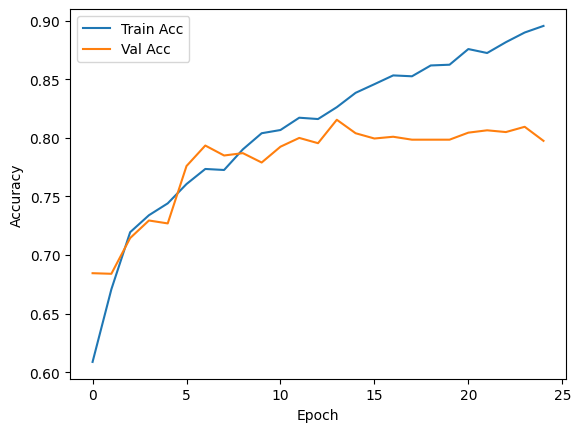

In [14]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

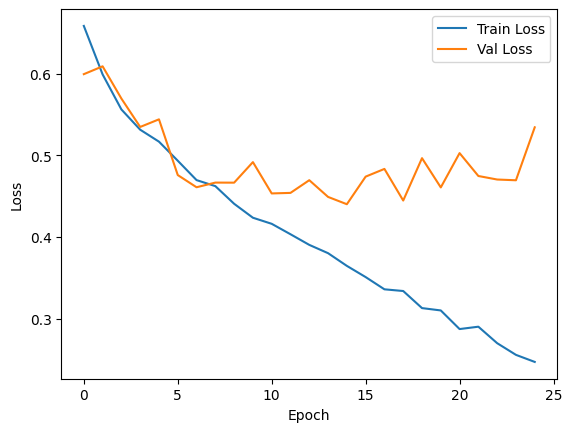

In [15]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [16]:
acc = history.history['accuracy']
val = history.history['val_accuracy']
print(f"Train Acc akhir: {acc[-1]:.4f} | terbaik: {max(acc):.4f}")
print(f"Val Acc   akhir: {val[-1]:.4f} | terbaik: {max(val):.4f}")

Train Acc akhir: 0.8956 | terbaik: 0.8956
Val Acc   akhir: 0.7975 | terbaik: 0.8155


## Langkah 5 - Prediksi dengan 1 Citra

In [17]:
from tensorflow.keras.preprocessing import image

test_image = image.load_img('dataset/single_prediction/cat_or_dog_1.jpg', target_size = (64, 64))
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)
result = cnn.predict(test_image, verbose = 0)
print(training_set.class_indices)
print("Probabilitas dog:", result[0][0])
if result[0][0] == 1:
  prediction = 'dog'
else:
  prediction = 'cat'
print("Prediksi:", prediction)

{'cats': 0, 'dogs': 1}
Probabilitas dog: 1.0
Prediksi: dog


`np.expand_dims(..., axis=0)` menambah satu dimensi di depan karena `predict` menerima batch citra, bukan satu citra. Bentuk akhirnya menjadi (1, 64, 64, 3).

Catatan penting: generator melatih model pada citra yang sudah dibagi 255, sedangkan `image.img_to_array` masih bernilai 0-255. Modul tidak melakukan `rescale`, dan pada model ini hasilnya tetap benar karena nilai yang jauh lebih besar hanya membuat neuron lebih yakin; tetapi untuk model lain skala yang tidak cocok bisa membuat prediksi kacau. Baris `test_image = test_image / 255.0` ditambahkan di sel berikut agar konsisten dengan data latih.

In [18]:
test_image_scaled = test_image / 255.0
result_scaled = cnn.predict(test_image_scaled, verbose = 0)
print("Probabilitas dog (setelah rescale):", result_scaled[0][0])

Probabilitas dog (setelah rescale):

 0.99999964


cat_or_dog_1.jpg: prob dog = 1.0000 -> dog


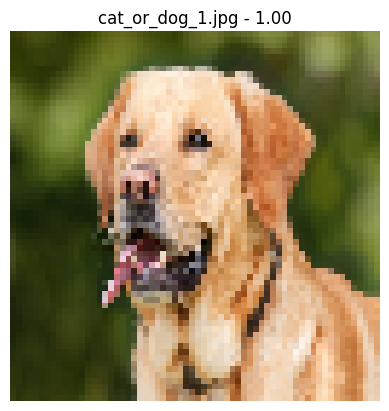

cat_or_dog_2.jpg: prob dog = 0.1743 -> cat


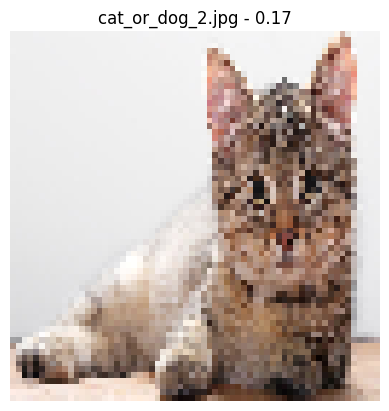

In [19]:
for fname in ['cat_or_dog_1.jpg', 'cat_or_dog_2.jpg']:
    img = image.load_img(f'dataset/single_prediction/{fname}', target_size = (64, 64))
    arr = np.expand_dims(image.img_to_array(img), axis = 0) / 255.0
    p = cnn.predict(arr, verbose = 0)[0][0]
    print(f"{fname}: prob dog = {p:.4f} -> {'dog' if p > 0.5 else 'cat'}")

    plt.imshow(image.load_img(f'dataset/single_prediction/{fname}', target_size = (64, 64)))
    plt.title(f"{fname} - {p:.2f}")
    plt.axis('off')
    plt.show()

## Evaluasi pada Data Uji

In [20]:
test_loss, test_acc = cnn.evaluate(test_set, verbose = 0)
print("Loss test:", test_loss)
print("Akurasi test:", test_acc)

Loss test: 0.5342152714729309
Akurasi test: 0.7975000143051147


In [21]:
from sklearn.metrics import confusion_matrix, classification_report

# generator terpisah tanpa shuffle: urutan prediksi harus sama dengan urutan test_set.classes
eval_set = test_datagen.flow_from_directory('dataset/test_set',
                                            target_size = (64, 64),
                                            batch_size = 32,
                                            class_mode = 'binary',
                                            shuffle = False)
y_prob = cnn.predict(eval_set, verbose = 0)
y_pred = (y_prob > 0.5).astype(int).ravel()
y_true = eval_set.classes

print(classification_report(y_true, y_pred, target_names=['cat', 'dog']))
print(confusion_matrix(y_true, y_pred))

Found 2000 images belonging to 2 classes.


              precision    recall  f1-score   support

         cat       0.86      0.71      0.78      1000
         dog       0.75      0.89      0.81      1000

    accuracy                           0.80      2000
   macro avg       0.81      0.80      0.80      2000
weighted avg       0.81      0.80      0.80      2000

[[708 292]
 [113 887]]


### Interpretasi

Akurasi uji 0.7975 dengan akurasi latih 0.8956. Selisih sekitar 10 poin itu tanda overfitting ringan, dan penyebabnya masuk akal: 8000 citra latih untuk dua blok konvolusi. Augmentasi pada Langkah 2 yang menahan overfitting agar tidak lebih parah.

Laporan per kelas memperlihatkan model condong ke `dogs`: recall dog 0.89 tetapi recall cat hanya 0.71, sehingga 292 citra kucing salah disebut anjing. Sebagian citra kucing memang berpose mirip anjing, dan sebaliknya.

Dua cara memperbaiki tanpa mengubah konsep: menambah blok konvolusi ketiga dengan filter 64, atau memakai dropout 0.5 sebelum output. Pada tugas lab, perbaikan serupa (BatchNormalization, Dropout, augmentasi) dipakai untuk menaikkan akurasi CIFAR-10.